# Calibration

In [21]:
import cv2
import hashlib
import numpy as np 
from tqdm import tqdm
import matplotlib.pyplot as plt

In [22]:
# Generating a personalized random seed
username = "prit.kanadiya"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print(seed)

np.random.seed(42)

1379217023


In [23]:
def backward_energy(img, visualize=False):
    """
    Energy map using sobel filter
    """
    xgrad = cv2.Sobel(img, cv2.CV_32F, dx=1, dy=0, ksize=3, borderType=cv2.BORDER_DEFAULT)
    ygrad = cv2.Sobel(img, cv2.CV_32F, dx=0, dy=1, ksize=3, borderType=cv2.BORDER_DEFAULT)
    back_energy = np.sqrt(np.sum(xgrad**2, axis=2) + np.sum(ygrad**2, axis=2))

    if (visualize):
        # cv2.imwrite("backward_energy.jpg", back_energy)
        plt.imshow(back_energy, cmap="gray")
        plt.show()

    return back_energy

In [24]:
def forward_energy(img, visualize=False):
    """
    Energy map using backward energy and the intensity difference created by removing the pixel
    """

    back_energy = backward_energy(img)

    for_energy = back_energy.copy()

    for i in range(1, img.shape[0]):
        for j in range(img.shape[1]):

            if (j == 0):    # Here, we can only account for top and right
                cU = for_energy[i-1, j]
                cR = for_energy[i-1, j+1] + np.sum(np.abs(img[i, j] - img[i, j+1]))
                min_cost = min(cU, cR)

            elif (j == img.shape[1] - 1):    # Here, we can only account for top and left
                cU = for_energy[i-1, j]
                cL = for_energy[i-1, j-1] + np.sum(np.abs(img[i, j] - img[i, j-1]))
                min_cost = min(cU, cL)

            else:    # Here, we can account for top, right and left
                cU = for_energy[i-1, j]
                cL = for_energy[i-1, j-1] + np.sum(np.abs(img[i, j] - img[i, j-1]))
                cR = for_energy[i-1, j+1] + np.sum(np.abs(img[i, j] - img[i, j+1]))
                min_cost = min(cL, cU, cR)
        
            for_energy[i][j] += min_cost
    
    if (visualize):
        for_energy = cv2.normalize(for_energy, None, 0, 255, cv2.NORM_MINMAX)
        plt.imshow(for_energy, cmap="gray")
        plt.show()

    return for_energy

In [25]:
def temporal_energy(frames):
    temp_energy = np.zeros((frames[0].shape[0], frames[0].shape[1]), dtype=np.float32)
    for t in range(1, len(frames)):
        diff = np.abs(frames[t].astype(np.float32) - frames[t-1].astype(np.float32))
        temp_energy = np.maximum(temp_energy, diff.sum(axis=2))
    return temp_energy

In [26]:
def normalize_image(img):
    return img.astype(np.float32) / 255.0

def normalize_energy(E):
    E = E.astype(np.float32)
    return (E - E.min()) / (E.max() - E.min() + 1e-8)

def resize_spatially(img, target_shape):
    target_h, target_w = target_shape
    return cv2.resize(img, (target_w, target_h), interpolation=cv2.INTER_LINEAR)

In [27]:
def sample_frames(video_path, num_samples = 5):
    cap = cv2.VideoCapture(video_path)
    sampled_frames = []

    if not cap.isOpened():
        print(f"Could not open {video_path}")
    else: 
        frames = []
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            frames.append(frame)

    cap.release()

    # sample_ids = np.random.choice(len(frames), size=num_samples, replace=False)    # Random sampling
    sample_ids = np.linspace(0, len(frames) - 1, num_samples, dtype=int)    # Systematic sampling
    h, w = frames[0].shape[:2]
    for i in sample_ids:
        frame = frames[i]
        resized = cv2.resize(frame, (w // 2, h // 2), interpolation=cv2.INTER_LINEAR)    # To make computation faster, we do search on reduced image
        sampled_frames.append(resized)

    return sampled_frames


In [ ]:
def find_vertical_stream(energy, stream_width):

    max_starting_position = energy.shape[1] - stream_width    # For (i, j), we evaluate cost till (i, j+stream_width)

    # Calculating prefix sums for easy computation
    prefix = np.zeros((energy.shape[0], energy.shape[1] + 1), dtype=np.float32)
    prefix[:, 1:] = np.cumsum(energy, axis=1)    # The first column is 0s

    def stream_cost(i, j):
        return prefix[i, j + stream_width] - prefix[i, j]
    
    dp = np.full((energy.shape[0], max_starting_position + 1), np.inf, dtype=np.float32)
    back = np.zeros((energy.shape[0], max_starting_position + 1), dtype=np.int32)

    # The first row remains as it is
    for j in range(max_starting_position + 1):
        dp[0, j] = stream_cost(0, j)

    for i in range(1, energy.shape[0]):
        for j in range(max_starting_position + 1):
            best_prev = dp[i - 1, j]
            best_idx = j

            if j > 0 and dp[i - 1, j - 1] < best_prev:
                best_prev = dp[i - 1, j - 1]
                best_idx = j - 1

            if j < max_starting_position and dp[i - 1, j + 1] < best_prev:
                best_prev = dp[i - 1, j + 1]
                best_idx = j + 1

            dp[i, j] = stream_cost(i, j) + best_prev
            back[i, j] = best_idx

    seams = np.zeros(energy.shape[0], dtype=np.int32)
    j = np.argmin(dp[-1])
    seams[-1] = j

    for i in range(energy.shape[0] - 2, -1, -1):
        j = back[i + 1, j]
        seams[i] = j

    return seams

def find_horizontal_stream(energy, stream_width):
    seams_v = find_vertical_stream(energy.T, stream_width)  
    seams_h = [seam.copy() for seam in seams_v]      
    return seams_h

In [ ]:
def visualize_vertical_stream(img, seam, stream_width):
    visualization_img = img.copy()
    for i in range(len(seam)):
        max_start = img.shape[1] - stream_width
        j_start = min(seam[i], max_start)
        j_end = min(j_start + stream_width, visualization_img.shape[1])
        visualization_img[i, j_start:j_end, :] = (255, 0, 0)  
    return visualization_img


def visualize_horizontal_stream(img, seam, stream_width):
    visualization_img = img.copy()
    for i in range(len(seam)):
        max_start = img.shape[0] - stream_width
        i_start = min(seam[i], max_start)
        i_end = min(i_start + stream_width, visualization_img.shape[0])
        visualization_img[i_start:i_end, i, :] = (0, 0, 255)
    return visualization_img


In [ ]:
def remove_vertical_stream(img, seam_left, stream_width):
    out_img = np.zeros((img.shape[0], img.shape[1] - stream_width, img.shape[2]), dtype=img.dtype)
    for i in range(img.shape[0]):
        j_start = seam_left[i]
        j_end = min(j_start + stream_width, img.shape[1])
        out_img[i, :, :] = np.delete(img[i, :, :], np.s_[j_start:j_end], axis=0)

    return out_img

def remove_horizontal_stream(img, seam_top, stream_width):
    img_T = img.transpose(1, 0, 2)  
    out_T = remove_vertical_stream(img_T, seam_top, stream_width)
    return out_T.transpose(1, 0, 2)  


In [ ]:
def resize(img, target_h, target_w, stream_width, visualize = False):
    modified_img = img.copy()
    num_vertical_seams = img.shape[1] - target_w
    num_horizontal_seams = img.shape[0] - target_h

    if (visualize):
        visualization_frames = []

    while num_vertical_seams > 0 or num_horizontal_seams > 0:
        energy = forward_energy(modified_img)

        # This is to ensure that we cover the residual band if stream_width is large
        vertical_width = min(stream_width, num_vertical_seams)
        horizontal_width = min(stream_width, num_horizontal_seams)

        if vertical_width > 0 and horizontal_width == 0:
            seam = find_vertical_stream(energy, vertical_width)
            if (visualize):
                visualization_img = visualize_vertical_stream(modified_img, seam, vertical_width)
                visualization_resized = cv2.resize(visualization_img, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)    # For visualization in form of video
                visualization_frames.append(visualization_resized)
            modified_img = remove_vertical_stream(modified_img, seam, vertical_width)
            num_vertical_seams -= vertical_width
            continue

        if horizontal_width > 0 and vertical_width == 0:
            seam = find_vertical_stream(energy.T, horizontal_width)
            if (visualize):
                visualization_img = visualize_horizontal_stream(modified_img, seam, horizontal_width)
                visualization_resized = cv2.resize(visualization_img, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
                visualization_frames.append(visualization_resized)
            modified_img = remove_horizontal_stream(modified_img, seam_top, horizontal_width)
            num_horizontal_seams -= horizontal_width
            continue

        seam_left = find_vertical_stream(energy, vertical_width)
        vertical_cost = sum(energy[i, seam_left[i]:seam_left[i]+vertical_width].sum() for i in range(energy.shape[0]))

        seam_top = find_vertical_stream(energy.T, horizontal_width)
        horizontal_cost = sum(energy.T[j, seam_top[j]:seam_top[j]+horizontal_width].sum() for j in range(energy.shape[1]))

        if vertical_cost <= horizontal_cost:
            if (visualize):
                visualization_img = visualize_vertical_stream(modified_img, seam_left, vertical_width)
                visualization_resized = cv2.resize(visualization_img, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
                visualization_frames.append(visualization_resized)
            modified_img = remove_vertical_stream(modified_img, seam_left, vertical_width)
            num_vertical_seams -= vertical_width
        else:
            if (visualize):
                visualization_img = visualize_horizontal_stream(modified_img, seam_top, horizontal_width)
                visualization_resized = cv2.resize(visualization_img, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
                visualization_frames.append(visualization_resized)
            modified_img = remove_horizontal_stream(modified_img, seam_top, horizontal_width)
            num_horizontal_seams -= horizontal_width

    if (visualize):
        return modified_img, visualization_frames
    else:
        return modified_img

In [32]:
def save_video(frames, output_path, fps=30):
    h, w, c = frames[0].shape
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    writer = cv2.VideoWriter(output_path, fourcc, fps, (w, h), isColor=True)

    for f in frames:
        writer.write(f)
    writer.release()
    
    print(f"Saved output video to {output_path}")

In [33]:
def evaluate_metrics(videoA_frames, videoB_frames, alpha=0.5):
    num_frames = min(len(videoA_frames), len(videoB_frames))

    videoA_frames = [normalize_image(f) for f in videoA_frames]
    videoB_frames = [normalize_image(f) for f in videoB_frames]
    
    forward_diffs = []
    for i in range(num_frames):
        frameA = videoA_frames[i]
        frameB = videoB_frames[i]

        if frameA.shape[:2] != frameB.shape[:2]:
            frameB = resize_spatially(frameB, frameA.shape[:2])

        fwdA = backward_energy(frameA)
        fwdB = backward_energy(frameB)
        fwdA = [normalize_energy(f) for f in fwdA]
        fwdB = [normalize_energy(f) for f in fwdB]
        fwdA = np.array(fwdA)
        fwdB = np.array(fwdB)
        forward_diffs.append(((fwdA - fwdB)**2).mean())

    avg_forward_diff = np.mean(forward_diffs)

    tempA = temporal_energy(videoA_frames[:num_frames])
    tempB = temporal_energy(videoB_frames[:num_frames])

    if tempA.shape != tempB.shape:
        tempB = resize_spatially(tempB, tempA.shape)

    tempA = [normalize_energy(f) for f in tempA]
    tempB = [normalize_energy(f) for f in tempB]
    tempA = np.array(tempA)
    tempB = np.array(tempB)
    temporal_diff = ((tempA - tempB)**2).mean()

    loss = alpha*avg_forward_diff + (1 - alpha)*(temporal_diff)

    return loss

In [34]:
def get_corners(img, thresh_ratio=0.02):
    frame_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    frame_gray = np.float32(frame_gray)

    blockSize = 2
    ksize = 3
    k = 0.04
    dst = cv2.cornerHarris(frame_gray, blockSize, ksize, k)
    dst = cv2.dilate(dst, None)

    threshold = thresh_ratio * dst.max()
    corner_mask = dst > threshold
    num_points = corner_mask.sum()

    return num_points


In [35]:
def evaluate_corners(videoA_frames, videoB_frames):
    original_video_num_points = []
    retargeted_video_num_points = []

    for frame_idx in range(len(videoA_frames)):
        original_frame_num_points = get_corners(videoA_frames[frame_idx])
        retargeted_frame_num_points = get_corners(videoB_frames[frame_idx])

        original_video_num_points.append(original_frame_num_points)
        retargeted_video_num_points.append(retargeted_frame_num_points)

    # Normalizing all the values
    K = max(original_video_num_points)
    original_norm = original_video_num_points / (K*1.0)
    retargeted_norm = retargeted_video_num_points / (K*1.0)

    # Computing MSE
    mse_original_retargeted = np.mean((original_norm - retargeted_norm) ** 2)

    return mse_original_retargeted

In [ ]:
def find_optimal_width(video_path, num_samples, stream_widths, target_h, target_w):
    sampled_frames = sample_frames(video_path, num_samples)

    max_h = sampled_frames[0].shape[0] - target_h
    max_w = sampled_frames[0].shape[1] - target_w
    max_stream_width = min(max_h, max_w)
    print(f"Maximum Stream Width: {max_stream_width}")

    valid_stream_widths = [bw for bw in stream_widths if bw <= max_stream_width]

    metric_losses = []
    corner_losses = []
    for stream_width in tqdm(valid_stream_widths):
        modified_frames = []

        for frame in sampled_frames:
            modified_frame = resize(frame, target_h, target_w, stream_width)
            modified_frames.append(modified_frame)
        
        metric_loss = evaluate_metrics(sampled_frames, modified_frames)
        corner_loss = evaluate_corners(sampled_frames, modified_frames)

        metric_losses.append(metric_loss)
        corner_losses.append(corner_loss)
    
    metric_losses_norm = (np.array(metric_losses) - np.min(metric_losses)) / (np.max(metric_losses) - np.min(metric_losses))
    corner_losses_norm = (np.array(corner_losses) - np.min(corner_losses)) / (np.max(corner_losses) - np.min(corner_losses))
    overall_losses_norm = metric_losses_norm + corner_losses_norm

    return metric_losses_norm, corner_losses_norm, overall_losses_norm, valid_stream_widths

In [ ]:
video_path = "../assets/input/golf.mov"    # (83, 240, 320, 3)
# video_path = "../assets/input/ratatouille1.mov"    # (64, 256, 640, 3)
num_samples = 20    # This is quater of the original video
target_h = 200
target_w = 200
stream_widths = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]    # These are for interpolated images

metric_losses_norm, corner_losses_norm, overall_losses_norm, valid_stream_widths = find_optimal_width(video_path, num_samples, stream_widths, target_h // 2, target_w // 2)    # we do // 2 because we are working on interpolated image interally

Maximum Bundle Width: 20


100%|██████████| 4/4 [01:29<00:00, 22.31s/it]


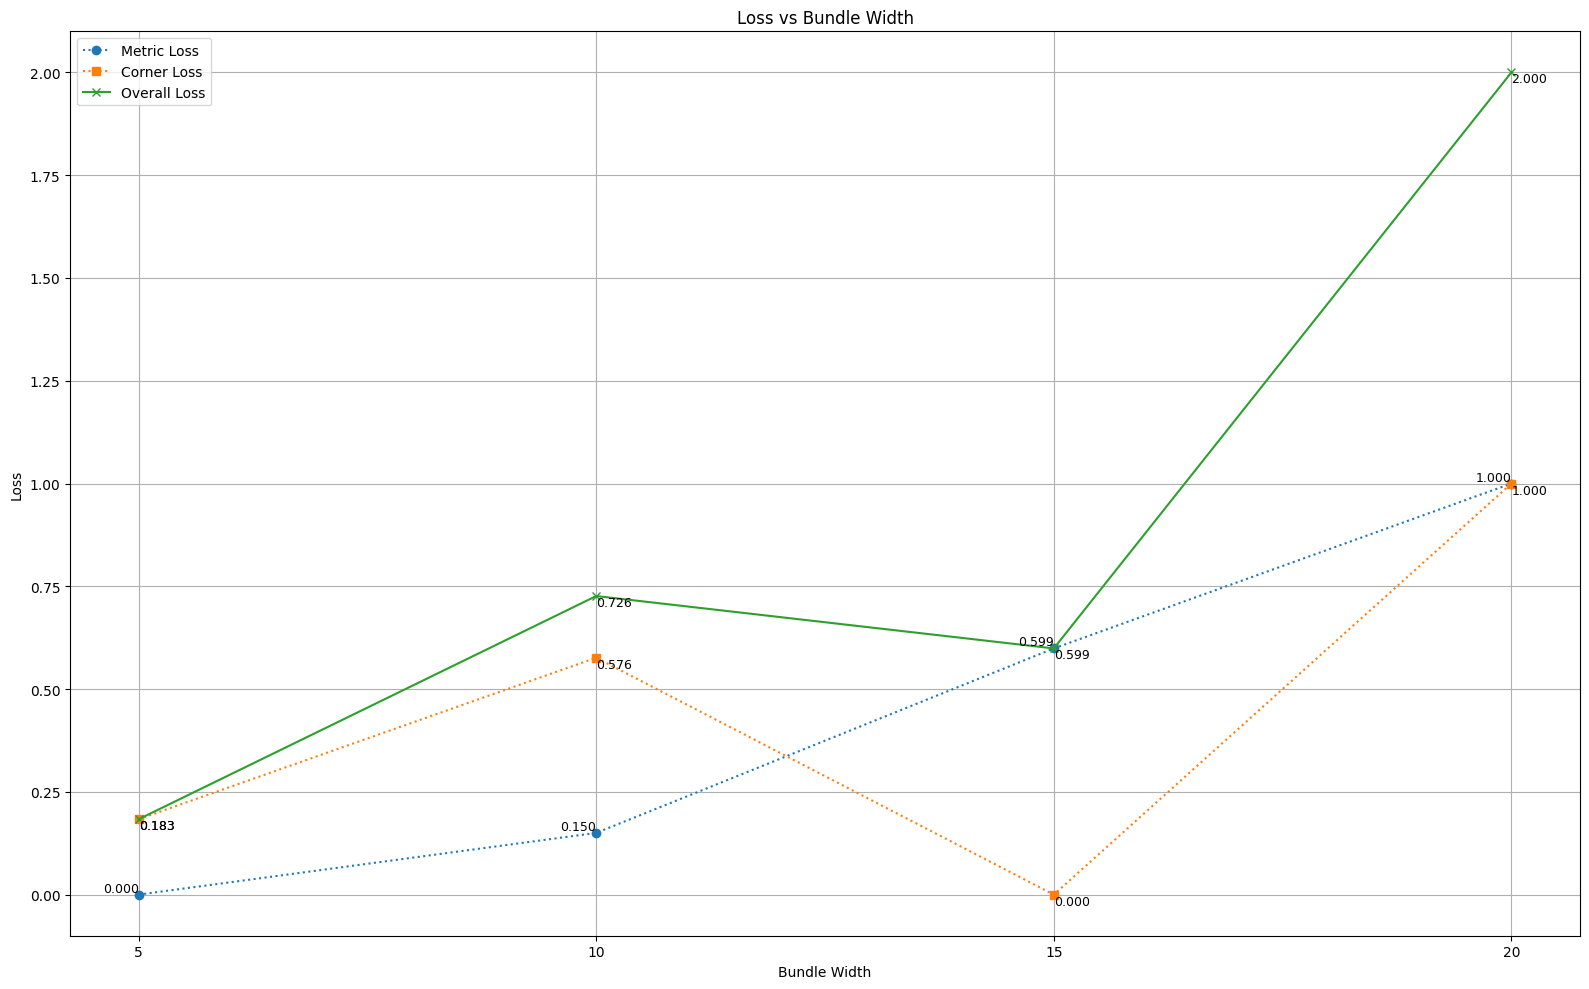

In [ ]:
plt.figure(figsize=(16, 10))
plt.plot(valid_stream_widths, metric_losses_norm, marker='o', label='Metric Loss', linestyle=':')
plt.plot(valid_stream_widths, corner_losses_norm, marker='s', label='Corner Loss', linestyle=':')
plt.plot(valid_stream_widths, overall_losses_norm, marker='x', label='Overall Loss')

for x, y in zip(valid_stream_widths, metric_losses_norm):
    plt.text(
        x, y, f"{y:.3f}",
        fontsize=9,
        ha='right', va='bottom'
    )
for x, y in zip(valid_stream_widths, corner_losses_norm):
    plt.text(
        x, y, f"{y:.3f}",
        fontsize=9,
        ha='left', va='top'
    )
for x, y in zip(valid_stream_widths, overall_losses_norm):
    plt.text(
        x, y, f"{y:.3f}",
        fontsize=9,
        ha='left', va='top'
    )

plt.xlabel("Stream Width")
plt.ylabel("Loss")
plt.xticks(valid_stream_widths)
plt.title("Loss vs Stream Width")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("../assets/output/optimal-width-search-golf.png")
plt.show()